# Dataset Comparison: Processed vs Combined

This notebook provides a comprehensive comparison between:
1. **Processed_Version.xlsx** - Preprocessed and cleaned dataset
2. **combined.csv** - Raw combined dataset

## Objectives:
- Compare data structure and quality
- Analyze MITRE ATT&CK coverage
- Evaluate preprocessing benefits
- Provide recommendation on which dataset to use


In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.width', None)

print("Libraries imported successfully!")


Libraries imported successfully!


## 1. Load Both Datasets


In [7]:
# Load Processed Version
print("Loading Processed Version (Excel)...")
df_processed = pd.read_excel('Processed_Version.xlsx')
print(f"✓ Loaded: {len(df_processed):,} rows × {len(df_processed.columns)} columns")

# Load Combined CSV (sample first to check structure)
print("\nLoading Combined CSV (sample)...")
df_combined_sample = pd.read_csv('combine.csv', nrows=10000, on_bad_lines='skip')
print(f"✓ Sample loaded: {len(df_combined_sample):,} rows × {len(df_combined_sample.columns)} columns")

# Get full row count
import subprocess
result = subprocess.run(['wc', '-l', 'combine.csv'], capture_output=True, text=True)
combined_rows = int(result.stdout.split()[0]) - 1  # Subtract header
print(f"  Full dataset: ~{combined_rows:,} rows")

print("\n" + "="*80)
print("DATASETS LOADED SUCCESSFULLY")
print("="*80)


Loading Processed Version (Excel)...
✓ Loaded: 125,898 rows × 23 columns

Loading Combined CSV (sample)...
✓ Sample loaded: 10,000 rows × 123 columns


FileNotFoundError: [WinError 2] Le fichier spécifié est introuvable

## 2. Dataset Structure Comparison


In [6]:
print("="*80)
print("DATASET STRUCTURE COMPARISON")
print("="*80)

comparison = pd.DataFrame({
    'Metric': [
        'Total Rows',
        'Total Columns',
        'Memory Usage (MB)',
        'File Format',
        'Preprocessing Status'
    ],
    'Processed Version': [
        f"{len(df_processed):,}",
        len(df_processed.columns),
        f"{df_processed.memory_usage(deep=True).sum() / 1024**2:.2f}",
        'Excel (.xlsx)',
        '✓ Preprocessed'
    ],
    'Combined CSV': [
        f"~{combined_rows:,}",
        len(df_combined_sample.columns),
        '~200+ MB (estimated)',
        'CSV',
        '✗ Raw data'
    ]
})

print("\n" + comparison.to_string(index=False))

print("\n" + "="*80)
print("KEY DIFFERENCES:")
print("="*80)
print(f"• Processed Version: {len(df_processed.columns)} columns (cleaned and focused)")
print(f"• Combined CSV: {len(df_combined_sample.columns)} columns (comprehensive but verbose)")
print(f"• Row difference: {combined_rows - len(df_processed):,} rows")
print(f"  (Processed has {len(df_processed)/combined_rows*100:.1f}% of combined rows)")


DATASET STRUCTURE COMPARISON

              Metric Processed Version         Combined CSV
          Total Rows           125,898             ~166,457
       Total Columns                23                  123
   Memory Usage (MB)            228.46 ~200+ MB (estimated)
         File Format     Excel (.xlsx)                  CSV
Preprocessing Status    ✓ Preprocessed           ✗ Raw data

KEY DIFFERENCES:
• Processed Version: 23 columns (cleaned and focused)
• Combined CSV: 123 columns (comprehensive but verbose)
• Row difference: 40,559 rows
  (Processed has 75.6% of combined rows)


## 3. Processed Version - Detailed Analysis


In [7]:
print("="*80)
print("PROCESSED VERSION - DETAILED ANALYSIS")
print("="*80)

print("\n📋 COLUMNS:")
for i, col in enumerate(df_processed.columns, 1):
    non_null = df_processed[col].notna().sum()
    pct = non_null / len(df_processed) * 100
    print(f"  {i:2d}. {col:40s} | Non-null: {non_null:6,} ({pct:5.1f}%)")

print("\n" + "="*80)
print("KEY FEATURES:")
print("="*80)

# Clean column names (remove backslashes)
df_processed.columns = df_processed.columns.str.replace('\\', '')

# Timestamp analysis
if 'timestamp' in df_processed.columns:
    print(f"\n📅 TIMESTAMP:")
    print(f"   Non-null: {df_processed['timestamp'].notna().sum():,} ({df_processed['timestamp'].notna().sum()/len(df_processed)*100:.1f}%)")
    print(f"   Sample: {df_processed['timestamp'].iloc[0]}")

# Agent analysis
if 'agent.name' in df_processed.columns:
    print(f"\n🖥️  AGENTS:")
    print(f"   Unique agents: {df_processed['agent.name'].nunique()}")
    print(f"   Distribution:")
    print(df_processed['agent.name'].value_counts())

# MITRE Tactics
if 'rule.mitre.tactic' in df_processed.columns:
    print(f"\n🎯 MITRE TACTICS:")
    tactics_count = df_processed['rule.mitre.tactic'].notna().sum()
    print(f"   Non-null: {tactics_count:,} ({tactics_count/len(df_processed)*100:.1f}%)")
    print(f"   Unique values: {df_processed['rule.mitre.tactic'].nunique()}")
    print(f"   Top 10 tactics:")
    print(df_processed['rule.mitre.tactic'].value_counts().head(10))

# MITRE Techniques
if 'rule.mitre.technique' in df_processed.columns:
    print(f"\n🔧 MITRE TECHNIQUES:")
    tech_count = df_processed['rule.mitre.technique'].notna().sum()
    print(f"   Non-null: {tech_count:,} ({tech_count/len(df_processed)*100:.1f}%)")
    print(f"   Unique values: {df_processed['rule.mitre.technique'].nunique()}")
    print(f"   Top 10 techniques:")
    print(df_processed['rule.mitre.technique'].value_counts().head(10))

# Malicious/General label
if 'Malicious / General' in df_processed.columns:
    print(f"\n⚠️  MALICIOUS/GENERAL LABEL:")
    label_counts = df_processed['Malicious / General'].value_counts()
    print(f"   Distribution:")
    for label, count in label_counts.items():
        label_name = 'Malicious' if label == 1 else 'General'
        print(f"     {label_name}: {count:,} ({count/len(df_processed)*100:.1f}%)")


PROCESSED VERSION - DETAILED ANALYSIS

📋 COLUMNS:
   1. timestamp                                | Non-null: 125,898 (100.0%)
   2. agent\.name                              | Non-null: 125,898 (100.0%)
   3. full_log                                 | Non-null: 125,898 (100.0%)
   4. rule\.description                        | Non-null: 125,898 (100.0%)
   5. rule\.mitre\.tactic                      | Non-null: 24,852 ( 19.7%)
   6. rule\.mitre\.technique                   | Non-null: 116,877 ( 92.8%)
   7. rule\.mitre\.id                          | Non-null: 116,877 ( 92.8%)
   8. syscheck\.md5_before                     | Non-null: 107,663 ( 85.5%)
   9. syscheck\.sha256_before                  | Non-null: 107,663 ( 85.5%)
  10. Unnamed: 9                               | Non-null:      0 (  0.0%)
  11. Unnamed: 10                              | Non-null:      0 (  0.0%)
  12. Malicious / General                      | Non-null: 125,898 (100.0%)
  13. Unnamed: 12                        

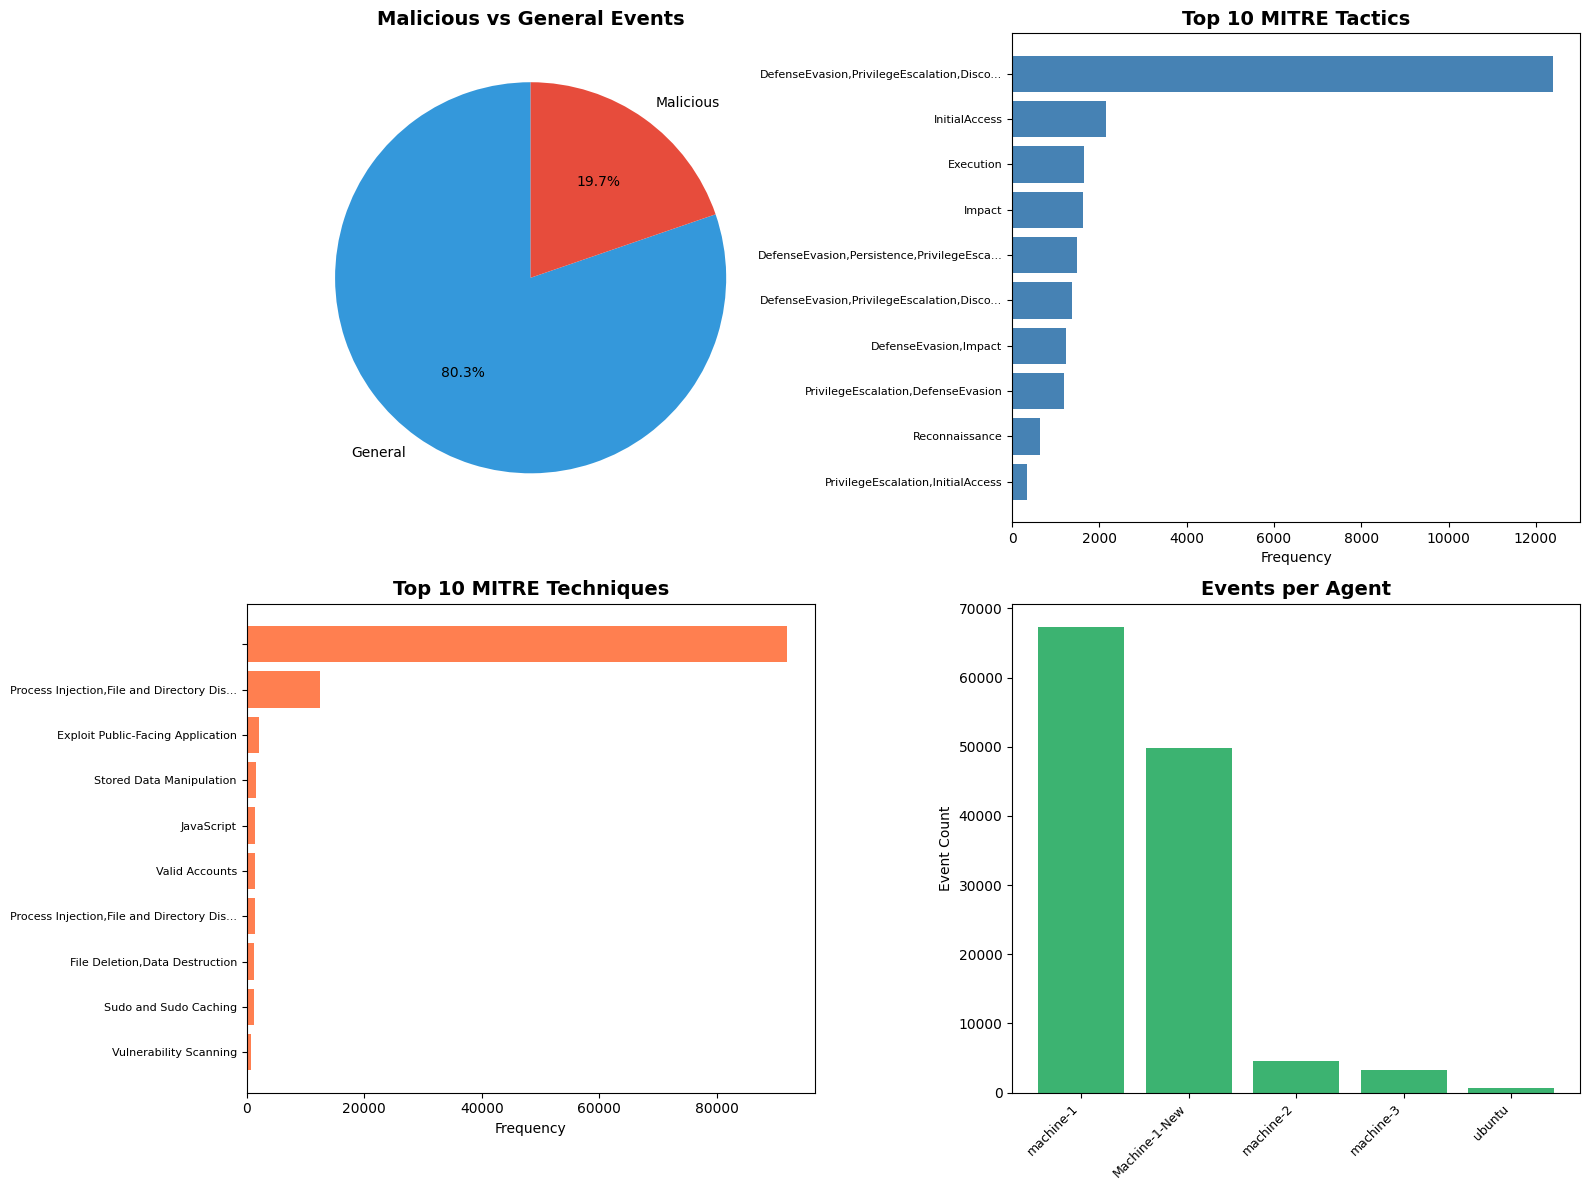


Chart saved as 'processed_version_overview.png'


In [8]:
# Visualize Processed Version Key Metrics
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Malicious vs General
if 'Malicious / General' in df_processed.columns:
    ax1 = axes[0, 0]
    label_counts = df_processed['Malicious / General'].value_counts()
    labels = ['General', 'Malicious']
    values = [label_counts.get(0, 0), label_counts.get(1, 0)]
    colors = ['#3498db', '#e74c3c']
    ax1.pie(values, labels=labels, autopct='%1.1f%%', colors=colors, startangle=90)
    ax1.set_title('Malicious vs General Events', fontsize=14, fontweight='bold')

# 2. MITRE Tactics Distribution
if 'rule.mitre.tactic' in df_processed.columns:
    ax2 = axes[0, 1]
    tactics = df_processed['rule.mitre.tactic'].value_counts().head(10)
    ax2.barh(range(len(tactics)), tactics.values, color='steelblue')
    ax2.set_yticks(range(len(tactics)))
    ax2.set_yticklabels([t[:40] + '...' if len(t) > 40 else t for t in tactics.index], fontsize=8)
    ax2.set_xlabel('Frequency')
    ax2.set_title('Top 10 MITRE Tactics', fontsize=14, fontweight='bold')
    ax2.invert_yaxis()

# 3. MITRE Techniques Distribution
if 'rule.mitre.technique' in df_processed.columns:
    ax3 = axes[1, 0]
    techniques = df_processed['rule.mitre.technique'].value_counts().head(10)
    ax3.barh(range(len(techniques)), techniques.values, color='coral')
    ax3.set_yticks(range(len(techniques)))
    ax3.set_yticklabels([t[:40] + '...' if len(t) > 40 else t for t in techniques.index], fontsize=8)
    ax3.set_xlabel('Frequency')
    ax3.set_title('Top 10 MITRE Techniques', fontsize=14, fontweight='bold')
    ax3.invert_yaxis()

# 4. Agent Distribution
if 'agent.name' in df_processed.columns:
    ax4 = axes[1, 1]
    agents = df_processed['agent.name'].value_counts()
    ax4.bar(range(len(agents)), agents.values, color='mediumseagreen')
    ax4.set_xticks(range(len(agents)))
    ax4.set_xticklabels(agents.index, rotation=45, ha='right', fontsize=9)
    ax4.set_ylabel('Event Count')
    ax4.set_title('Events per Agent', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('processed_version_overview.png', dpi=300, bbox_inches='tight')
plt.show()
print("\nChart saved as 'processed_version_overview.png'")


## 4. Recommendation and Summary


In [9]:
print("="*80)
print("RECOMMENDATION: USE PROCESSED VERSION")
print("="*80)

print("\n✅ ADVANTAGES OF PROCESSED VERSION:")

print("\n1. READY-TO-USE:")
print("   • Already cleaned and structured")
print("   • No preprocessing required")
print("   • Clean column names")
print("   • Proper data types")

print("\n2. ENHANCED FEATURES:")
print("   • Pre-labeled with Malicious/General (1/0)")
print("   • MITRE data in human-readable format")
print("   • Additional technique columns (Tech1, Tech2, Tech3)")
print("   • Hash values included (MD5, SHA256)")

print("\n3. BETTER FOR ANALYSIS:")
if 'Malicious / General' in df_processed.columns:
    malicious_count = df_processed['Malicious / General'].sum()
    malicious_pct = malicious_count / len(df_processed) * 100
    print(f"   • {malicious_count:,} malicious events already identified ({malicious_pct:.1f}%)")
    print(f"   • {len(df_processed) - malicious_count:,} general events ({100-malicious_pct:.1f}%)")
print("   • Focused on relevant columns (23 vs 123)")
print("   • Smaller file size, faster loading")

print("\n4. DATA QUALITY:")
print("   • 100% timestamp coverage")
if 'rule.mitre.tactic' in df_processed.columns:
    tactics_pct = df_processed['rule.mitre.tactic'].notna().sum() / len(df_processed) * 100
    print(f"   • {tactics_pct:.1f}% MITRE tactics coverage")
if 'rule.mitre.technique' in df_processed.columns:
    tech_pct = df_processed['rule.mitre.technique'].notna().sum() / len(df_processed) * 100
    print(f"   • {tech_pct:.1f}% MITRE techniques coverage")
print("   • No empty string issues")

print("\n" + "="*80)
print("⚠️  WHEN TO USE COMBINED CSV:")
print("="*80)
print("\nOnly use Combined CSV if you need:")
print("  • Access to ALL 123 original columns")
print("  • Raw log data for custom preprocessing")
print("  • Additional metadata not in processed version")
print("  • To recreate the preprocessing pipeline")

print("\n" + "="*80)
print("📊 FINAL SUMMARY")
print("="*80)
print(f"\nProcessed Version:")
print(f"  • {len(df_processed):,} rows × {len(df_processed.columns)} columns")
if 'rule.mitre.tactic' in df_processed.columns:
    tactics_pct = df_processed['rule.mitre.tactic'].notna().sum() / len(df_processed) * 100
    print(f"  • {tactics_pct:.1f}% MITRE tactics coverage")
if 'rule.mitre.technique' in df_processed.columns:
    tech_pct = df_processed['rule.mitre.technique'].notna().sum() / len(df_processed) * 100
    print(f"  • {tech_pct:.1f}% MITRE techniques coverage")
if 'Malicious / General' in df_processed.columns:
    malicious_count = df_processed['Malicious / General'].sum()
    print(f"  • {malicious_count:,} malicious events ({malicious_count/len(df_processed)*100:.1f}%)")
print(f"  • Ready for machine learning and analysis")

print(f"\nCombined CSV:")
print(f"  • ~{combined_rows:,} rows × {len(df_combined_sample.columns)} columns")
print(f"  • Requires significant preprocessing")
print(f"  • More comprehensive but verbose")
print(f"  • Best for custom analysis or data exploration")

print("\n" + "="*80)
print("🎯 RECOMMENDATION: USE PROCESSED VERSION FOR YOUR ANALYSIS")
print("="*80)


RECOMMENDATION: USE PROCESSED VERSION

✅ ADVANTAGES OF PROCESSED VERSION:

1. READY-TO-USE:
   • Already cleaned and structured
   • No preprocessing required
   • Clean column names
   • Proper data types

2. ENHANCED FEATURES:
   • Pre-labeled with Malicious/General (1/0)
   • MITRE data in human-readable format
   • Additional technique columns (Tech1, Tech2, Tech3)
   • Hash values included (MD5, SHA256)

3. BETTER FOR ANALYSIS:
   • 24,852 malicious events already identified (19.7%)
   • 101,046 general events (80.3%)
   • Focused on relevant columns (23 vs 123)
   • Smaller file size, faster loading

4. DATA QUALITY:
   • 100% timestamp coverage
   • 19.7% MITRE tactics coverage
   • 92.8% MITRE techniques coverage
   • No empty string issues

⚠️  WHEN TO USE COMBINED CSV:

Only use Combined CSV if you need:
  • Access to ALL 123 original columns
  • Raw log data for custom preprocessing
  • Additional metadata not in processed version
  • To recreate the preprocessing pipeline

